In [71]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [72]:
import numpy as np
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square
from mytools.plot import (
    plot_heatmap,
    plot_stack_fit_res,
    plot_axlines,
    plot_hist,
    plot_line_diff,
    make_figure,
    set_ticks,
    plot_profile_2c,
)
from mytools.estimate import get_signal_level
from crafts_stack.halo_fitting import halofit
from crafts_stack.halo_models import build_model, apply_prior
from astropy.stats import sigma_clip
from mytools.data import read_h5, vitems

In [73]:
data_path = "../data/halo_subtracted_result_pca_halonew_pixweight_squaremask.h5"
vitems(data_path)

Item: crafts_df122k_rmfg0_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fit_weights
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/fitted
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/res
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg0_xsize3000_nfs10/stack
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10
Type: Group
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10/fit_mask
Type: Dataset
Shape: (120, 120)
Dtype: bool
Attributes (0):
 None
Item: crafts_df122k_rmfg10_xsize3000_nfs10/fit_weights
Type: Dataset
Shape: (120, 120)
Dtype: float64
Attributes (0):
 None
Item: crafts_df

<Axes: title={'center': 'Weights'}, xlabel='X', ylabel='Y'>

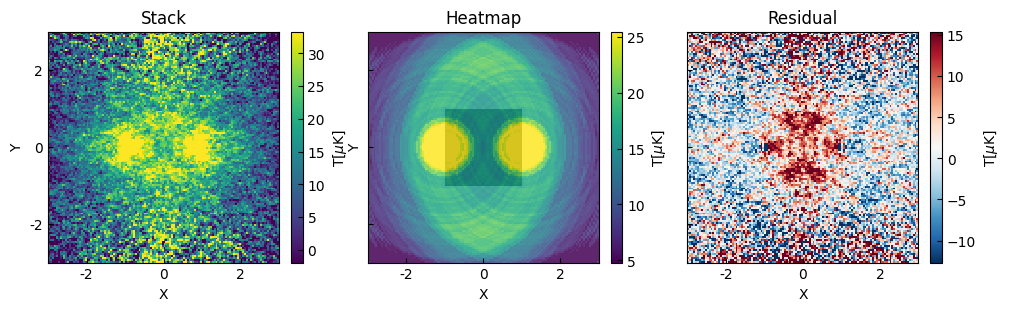

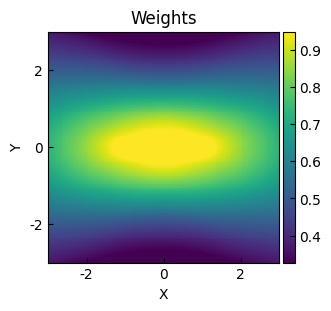

In [95]:
mode = 25
keys = [
    f"crafts_df122k_rmfg{mode}_xsize3000_nfs10/{k}"
    for k in ["stack", "fitted", "fit_weights", "fit_mask"]
]
stack, nfit, weights, mask = read_h5(data_path, keys)

plot_stack_fit_res(
    [stack, nfit, stack - nfit],
    title=["Stack", "Numerical fitting", "Residual"],
    fit_mask=mask,
)
plot_heatmap(weights, title="Weights", cbar_label="")

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(5.7546695036443225), np.float64(0.0), np.float64(0.75), np.float64(3.807711641933734)]
Gauss fit covariance: 
[[ 0.16692438  0.01081897 -0.12144589]
 [ 0.01081897  0.00526635 -0.02083419]
 [-0.12144589 -0.02083419  0.14322919]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 1587.441
Reduced chi-squared: 13.568
RMS residual: 3.637

width: 0.75
width_pix: 15


array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

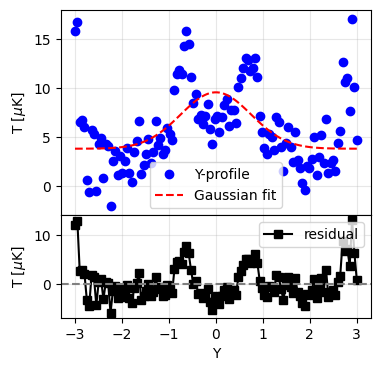

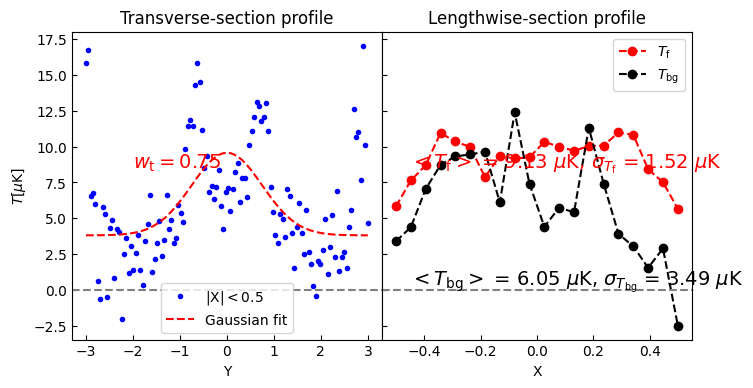

In [96]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.1, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(
    stack-nfit, weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True
)

text_pos = [
    [-0.45, 0.5 * np.max(ly[0])],
    [-0.45, -0.2 * np.min(ly[0])],
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8, 4), wspace=0.0, aspect=None, sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

In [110]:
coord = get_coord()

param_bg = {"degree": 2}

model = build_model('nfw', param_bg=param_bg) + build_model('lorentz')
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5, ellipticity=0., theta=0.)>

    [2]: <Lorentz2D(amplitude=50., x_mean=-1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [3]: <Lorentz2D(amplitude=50., x_mean=1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... y_mean_3 fwhm_3 ellipticity_3 theta_3
    ----------- -------- -------- ----- ... -------- ------ ------------- -------
           50.0     -1.0      0.0   0.5 ...      0.0    1.0           0.0     0.0


In [111]:
bounds = {
    # 'amplitude_0': (0, 200),
    # 'amplitude_1': (0, 200),
    # 'x_mean_0': (-1 - tolenrance, -1 + tolenrance),
    # 'x_mean_1': (1 - tolenrance, 1 + tolenrance),
    # 'y_mean_0': (0 - tolenrance, 0 + tolenrance),
    # 'y_mean_1': (0 - tolenrance, 0 + tolenrance),
    "ellipticity_0": (0, 0.5),
    "ellipticity_1": (0, 0.5),
    # 'theta_0': (0, 10),
    # 'theta_1': (0, 10),
    "r_s_0": (0.1, 2),
    "r_s_1": (0.1, 2),
}

constraints = {
    # "fixed": ['ellipticity_0', 'ellipticity_1', 'x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1'],
    "fixed": [
        "x_mean_0",
        "y_mean_0",
        "x_mean_1",
        "y_mean_1",
    ],  # fix the center of the two NFW profiles
    "tied": [
        ("amplitude_1", "amplitude_0"),  # amplitude_1 = amplitude_0
        ("ellipticity_1", "ellipticity_0"),
        # ("r_s_1", "r_s_2"),
        # ('c0_0_2', 'c0_0_3'),
        # ('c1_0_2', 'c1_0_3'),
        # ('c2_0_2', 'c2_0_3'),
        # ('c0_1_2', 'c0_1_3'),
        # ('c0_2_2', 'c0_2_3'),
        # ('c1_1_2', 'c1_1_3'),
    ],
}

model = apply_prior(model, bounds=bounds, constraints=constraints)
print(model.fixed)

{'amplitude_0': False, 'x_mean_0': True, 'y_mean_0': True, 'r_s_0': False, 'ellipticity_0': False, 'theta_0': False, 'amplitude_1': False, 'x_mean_1': True, 'y_mean_1': True, 'r_s_1': False, 'ellipticity_1': False, 'theta_1': False, 'amplitude_2': False, 'x_mean_2': False, 'y_mean_2': False, 'fwhm_2': False, 'ellipticity_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': False, 'y_mean_3': False, 'fwhm_3': False, 'ellipticity_3': False, 'theta_3': False}


In [113]:
halo_smooth_result, fitted_model, fit_info = halofit(
    coord, nfit, model=model, print_model=True, weights=weights
)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3]
Components: 
    [0]: <NFW2D(amplitude=765.21577327, x_mean=-1., y_mean=0., r_s=0.10000654, ellipticity=0.27304255, theta=-1.57086172)>

    [1]: <NFW2D(amplitude=765.21577327, x_mean=1., y_mean=0., r_s=0.10000838, ellipticity=0.27304255, theta=-4.71248756)>

    [2]: <Lorentz2D(amplitude=13.75023859, x_mean=0.31923535, y_mean=-1.55690677, fwhm=5.47678114, ellipticity=0.21472797, theta=0.99761515)>

    [3]: <Lorentz2D(amplitude=13.74655169, x_mean=-0.32063524, y_mean=1.55688389, fwhm=5.47251691, ellipticity=0.21438856, theta=0.99873605)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...   ellipticity_3         theta_3      
    ----------------- -------- -------- ... ------------------ ------------------
    765.2157732666603     -1.0      0.0 ... 0.2143885601440477 0.9987360451168574

Goodness of fit:
Chi-squared: 1010155.378
Reduced chi-squared:

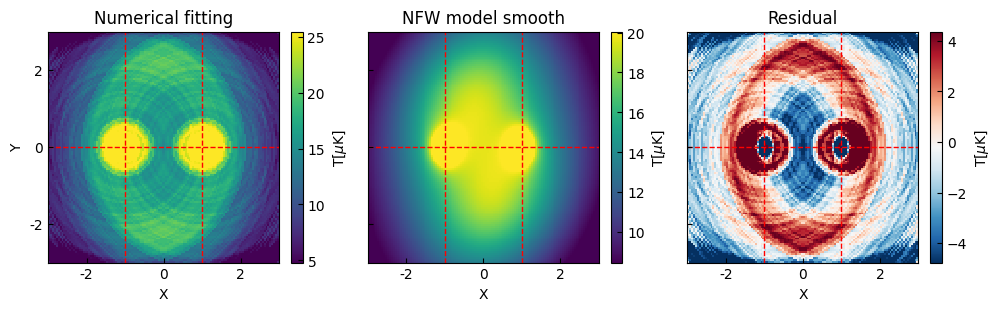

In [114]:
title = ["Numerical fitting", "NFW model smooth", "Residual"]
axes = plot_stack_fit_res(
    halo_smooth_result, title=title
)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

(-100.0, 100.0)

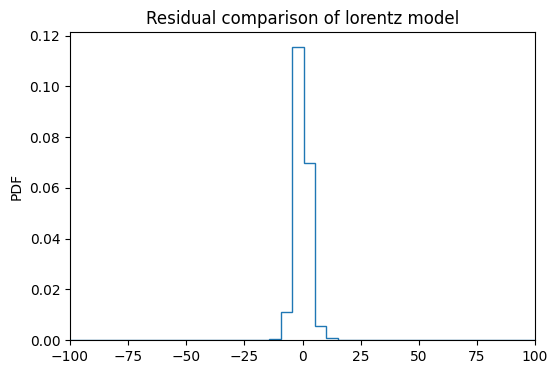

In [115]:
res_list = [halo_smooth_result[-1].flatten()]
title = "Residual comparison of %s model" % (name)
ax = plot_hist(res_list, bins=100, title=title)
ax.set_xlim(-100, 100)

# profiles

array([<Axes: title={'center': 'Stack'}, xlabel='X', ylabel='Y'>,
       <Axes: title={'center': 'Analytical fitting'}, xlabel='X'>,
       <Axes: title={'center': 'Residual'}, xlabel='X'>], dtype=object)

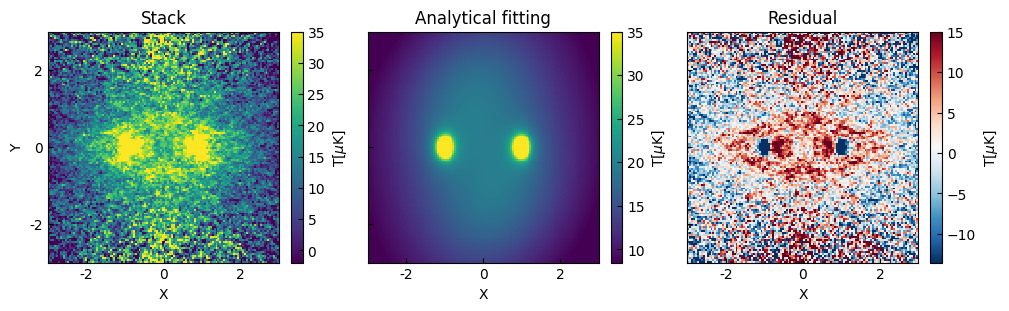

In [122]:
sfit = halo_smooth_result[1]

result = [stack, sfit, stack - sfit]
plot_stack_fit_res(result, title=["Stack", "Analytical fitting", "Residual"], vmax=[35, 35, 15])

In [117]:
get_yprofile = lambda dlist, ind: [x[ind, :] for x in dlist]
get_xprofile = lambda dlist, ind: [x[:, ind] for x in dlist]

lines_list = [
    get_yprofile(result[:2], 60),
    get_xprofile(result[:2], 40),
    get_xprofile(result[:2], 80),
]
title_list = ["Y=0", "X=-1", "X=1"]

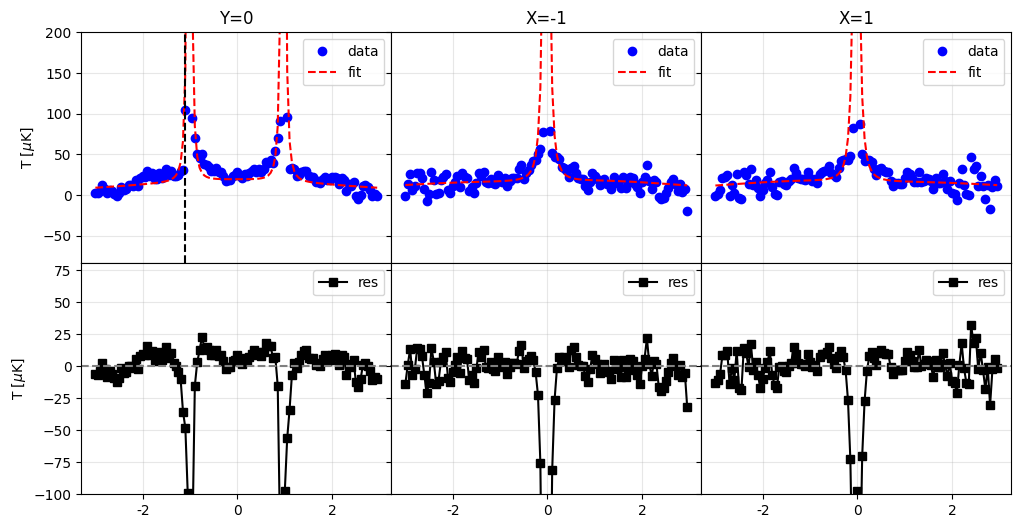

In [ ]:
fig, axes = make_figure(
    2,
    3,
    figsize=(12, 6),
    wspace=0.0,
    hspace=0.0,
    aspect=None,
    sharex=True,
    sharey="row",
)

for i, lines in enumerate(lines_list):
    _axes = [axes[0, i], axes[1, i]]

    plot_line_diff(
        *lines, title=title_list[i], axes=_axes, labels=["data", "fit", "res"]
    )

axes[0, 0].set_ylim(ymax=200)
axes[1, 0].set_ylim(ymin=-100)
axes[0, 0].set_ylabel(r"T [$\mu$K]")
axes[1, 0].set_ylabel(r"T [$\mu$K]")
set_ticks(axes[1, 0], share=False)

# estimate signal level

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(2.7385270519521243), np.float64(0.0), np.float64(0.6770785871017011), np.float64(3.793448997493593)]
Gauss fit covariance: 
[[ 0.14957978  0.01352516 -0.09590528]
 [ 0.01352516  0.0174714  -0.03265423]
 [-0.09590528 -0.03265423  0.11501399]]
2 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 1443.036
Reduced chi-squared: 12.334
RMS residual: 3.468

width: 0.6770785871017011
width_pix: 14


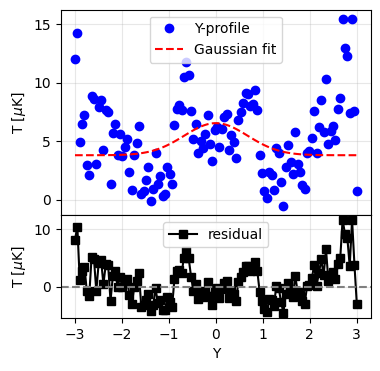

In [119]:
res = result[-1]
# res = stack - nfit
# bounds = (
#     [0, 0.1, -np.inf],
#     [np.inf, 0.7, np.inf],
# )
bounds = {
    "amplitude_0": (-np.inf, np.inf),  # amp > 0
    "stddev_0": (0.2, 0.75),  # sigma
}
lx, ly, clrb, params, cov = get_signal_level(
    res, weights, bounds=bounds, sigma_clip_sigma=3, show_fit=True
)
# lx, ly, clrb, params, cov = get_signal_level(res, bounds=bounds, sigma_clip_sigma=5, weights=weight[:,50:70].mean(axis=1), show_fit=False);
# lx, ly, clrb, params, cov = get_signal_level(res);

array([<Axes: title={'center': 'Transverse-section profile'}, xlabel='Y', ylabel='$T$[$\\mu$K]'>,
       <Axes: title={'center': 'Lengthwise-section profile'}, xlabel='X'>],
      dtype=object)

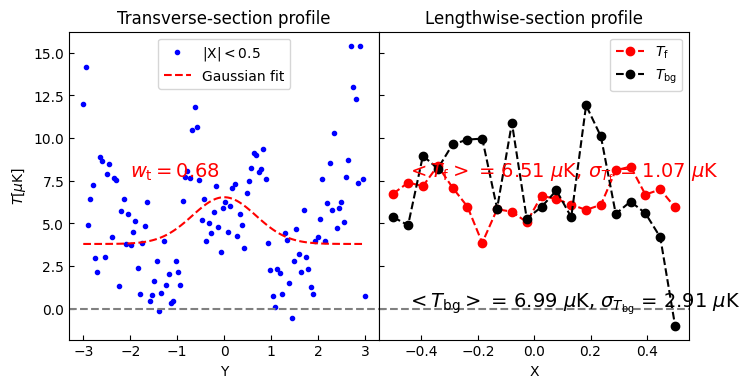

In [120]:
text_pos = [
    [-0.45, 0.5 * np.max(ly[0])],
    [-0.45, -0.2 * np.min(ly[0])],
    [-2, 0.5 * np.max(ly[0])],
]
fig, axes = make_figure(1, 2, figsize=(8, 4), wspace=0.0, aspect=None, sharex=False)
plot_profile_2c(lx, ly, axes=axes, width=params[2], text_pos=text_pos)

<Axes: title={'center': 'Signal level'}, ylabel='PDF'>

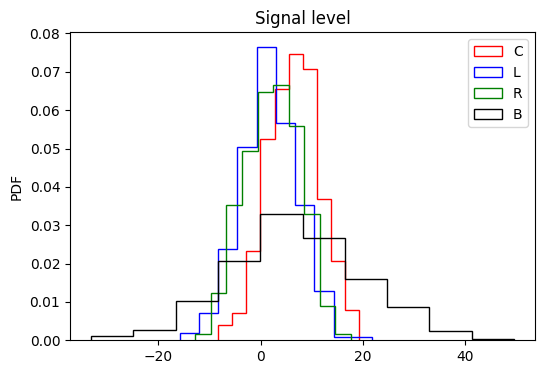

In [121]:
plot_hist(
    clrb, label=["C", "L", "R", "B"], color=["r", "b", "g", "k"], title="Signal level"
)